# Reviewer-response experiments: coupled nonlocal Fokker–Planck credit scoring

**Source:** Original UCI *Default of Credit Card Clients* dataset (30,000 rows). This notebook implements additional experiments requested by reviewers of the *Annals of Data Science* manuscript. It does **not** assume that new results will match previously reported manuscript values. All metrics are derived from predictions; no values are copied from manuscript tables.

**Design:** 60% training, 20% calibration/validation, 20% untouched test; stratified on outcome × sex. Classifier fitting uses training data; validation threshold and group-density post-processing use calibration data; test data are used only for evaluation. Original SEX=1 maps to group 0 (male), SEX=2 maps to group 1 (female). Positive class = no default next month. Group membership is excluded from predictive features.

**Scientific interpretation:** This is an explicit numerical model for a coupled fairness-driven drift with zero-flux boundaries, not an assertion that the exact undocumented original solver has been recovered. The analysis includes explicit and testable assumptions, and its empirical conclusions must be drawn from the generated outputs.

In [1]:
# pip install numpy pandas scipy scikit-learn xgboost openpyxl matplotlib
import time, json, platform
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.sparse import diags, eye
from scipy.sparse.linalg import splu
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score
from xgboost import XGBClassifier
SEED=42; np.random.seed(SEED)
DATA=Path('default of credit card clients.xlsx')
if not DATA.exists(): DATA=Path('/mnt/data/default of credit card clients(1).xlsx')
assert DATA.exists(), 'Put the original Excel dataset alongside this notebook.'
OUT=Path('reviewer_response_outputs'); OUT.mkdir(exist_ok=True)
print('Environment:',platform.python_version(),'Dataset:',DATA)


Environment: 3.14.6 Dataset: default of credit card clients.xlsx


## 1. Dataset, group mapping, and locked partitions

In [2]:
df=pd.read_excel(DATA,sheet_name='Data',header=1)
df.columns=[str(c).strip() for c in df.columns]
assert len(df)==30000 and df['ID'].is_unique
assert set(df['SEX'])=={1,2}
y=(1-df['default payment next month']).to_numpy(dtype=int)
g=(df['SEX'].to_numpy()==2).astype(int)
feature_cols=[c for c in df.columns if c not in ['ID','SEX','default payment next month']]
X=df[feature_cols].to_numpy(dtype=float)
strata=y*2+g
idx=np.arange(len(df))
train_idx,rest_idx=train_test_split(idx,test_size=.4,random_state=SEED,stratify=strata)
cal_idx,test_idx=train_test_split(rest_idx,test_size=.5,random_state=SEED,stratify=strata[rest_idx])
assert len(set(train_idx)&set(cal_idx))==0 and len(set(cal_idx)&set(test_idx))==0
print('Train / calibration / test:',len(train_idx),len(cal_idx),len(test_idx))
print('Group 0 = male (SEX=1); group 1 = female (SEX=2)')
display(pd.crosstab(pd.Series(g,name='group'),pd.Series(y,name='creditworthy')))
pd.DataFrame({'ID':df['ID'],'partition':np.where(np.isin(idx,train_idx),'train',np.where(np.isin(idx,cal_idx),'calibration','test'))}).to_csv(OUT/'partitions.csv',index=False)


Train / calibration / test: 18000 6000 6000
Group 0 = male (SEX=1); group 1 = female (SEX=2)


creditworthy,0,1
group,,
0,2873,9015
1,3763,14349


## 2. Traditional classifier baselines and XGBoost hyperparameters

In [3]:
models={
 'Logistic Regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=1500,random_state=SEED)),
 'Random Forest':RandomForestClassifier(n_estimators=250,min_samples_leaf=5,n_jobs=-1,random_state=SEED),
 'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=250,max_leaf_nodes=15,learning_rate=.05,random_state=SEED),
 'XGBoost':XGBClassifier(n_estimators=350,max_depth=3,learning_rate=.045,subsample=.85,colsample_bytree=.9,objective='binary:logistic',eval_metric='logloss',tree_method='hist',random_state=SEED,n_jobs=4)
}
scores={}; fit_times={}
for name,model in models.items():
    start=time.perf_counter(); model.fit(X[train_idx],y[train_idx]); fit_times[name]=time.perf_counter()-start
    scores[name]={'cal':model.predict_proba(X[cal_idx])[:,1], 'test':model.predict_proba(X[test_idx])[:,1]}
    print(name,round(fit_times[name],2),'seconds')
with open(OUT/'experiment_settings.json','w') as f:
    json.dump({'seed':SEED,'split':[.6,.2,.2],'group_mapping':{'0':'male (SEX=1)','1':'female (SEX=2)'},'positive_class':'no default','features':feature_cols,'models':{k:str(v.get_params()) for k,v in models.items()}},f,indent=2)


Logistic Regression 0.06 seconds
Random Forest 0.7 seconds
HistGradientBoosting 0.69 seconds
XGBoost 0.16 seconds


## 3. Fairness definitions and validation-selected thresholds

In [4]:
def safe_mean(a):return float(np.mean(a)) if len(a) else np.nan
def metrics(y_true,group,score,tau):
    pred=score>=tau
    app=[safe_mean(pred[group==k]) for k in (0,1)]
    tpr=[safe_mean(pred[(group==k)&(y_true==1)]) for k in (0,1)]
    fpr=[safe_mean(pred[(group==k)&(y_true==0)]) for k in (0,1)]
    return {'accuracy':accuracy_score(y_true,pred),'balanced_accuracy':balanced_accuracy_score(y_true,pred),
       'roc_auc':roc_auc_score(y_true,score),'pr_auc':average_precision_score(y_true,score),
       'approval_0':app[0],'approval_1':app[1],'tpr_0':tpr[0],'tpr_1':tpr[1],
       'fpr_0':fpr[0],'fpr_1':fpr[1],'dp_gap':app[0]-app[1],
       'abs_dp':abs(app[0]-app[1]),'abs_eo':abs(tpr[0]-tpr[1]),'abs_fpr':abs(fpr[0]-fpr[1]),
       'equalized_odds':max(abs(tpr[0]-tpr[1]),abs(fpr[0]-fpr[1]))}
def choose_tau(score,truth):
    candidates=np.linspace(.05,.95,901)
    vals=[balanced_accuracy_score(truth,score>=t) for t in candidates]
    return float(candidates[np.argmax(vals)])
taus={name:choose_tau(v['cal'],y[cal_idx]) for name,v in scores.items()}
benchmark=[]
for name,sc in scores.items():
    benchmark.append({'model':name,'threshold':taus[name],'train_seconds':fit_times[name],
                      **metrics(y[test_idx],g[test_idx],sc['test'],taus[name])})
bench=pd.DataFrame(benchmark);display(bench.round(5))
bench.to_csv(OUT/'classifier_benchmarks.csv',index=False)
# Assertions directly address reviewer #2's Table 5/6 discrepancy
assert np.allclose(bench.abs_eo,np.abs(bench.tpr_0-bench.tpr_1))
assert np.allclose(bench.abs_dp,np.abs(bench.approval_0-bench.approval_1))


,model,threshold,train_seconds,accuracy,balanced_accuracy,roc_auc,pr_auc,approval_0,approval_1,tpr_0,tpr_1,fpr_0,fpr_1,dp_gap,abs_dp,abs_eo,abs_fpr,equalized_odds
0,Logistic Regression,0.745,0.06107,0.75700,0.68158,0.72106,0.87541,0.70690,0.75594,0.79146,0.83275,0.44174,0.46277,-0.04904,0.04904,0.04129,0.02103,0.04129
1,Random Forest,0.783,0.69988,0.73033,0.70952,0.78002,0.91287,0.61901,0.67725,0.72102,0.76307,0.29913,0.34973,-0.05824,0.05824,0.04205,0.05060,0.05060
2,HistGradientBoosting,0.747,0.69376,0.78317,0.71106,0.78504,0.91467,0.72330,0.76256,0.82751,0.84843,0.39652,0.43484,-0.03927,0.03927,0.02092,0.03832,0.03832
3,XGBoost,0.763,0.15528,0.77033,0.71307,0.78551,0.91540,0.69092,0.74158,0.79590,0.82822,0.36174,0.41090,-0.05066,0.05066,0.03233,0.04917,0.04917


## 4. PDE solver with calibration-only densities

Let \(\rho_g(s,t)\) denote the group score density on \([0,1]\). Define \(\Delta=\int_\tau^1(\rho_0-\rho_1)ds\) and \(b_g=b_g^0-\lambda\eta_g\Delta\), with \(\eta_0=1\), \(\eta_1=-1\). We solve \(\partial_t\rho_g=-\partial_s(b_g\rho_g-D\partial_s\rho_g)\) with zero-flux boundaries using conservative upwind finite volumes and semi-implicit time stepping. The initial drift is calibrated to the initial density using a discrete zero-flux balance. The fairness energy monitored here is \(\Delta^2/2\); monotonic decay is evaluated rather than assumed.

In [5]:
def make_density(z,N):
    edges=np.linspace(0,1,N+1); h=1/N
    count,_=np.histogram(z,bins=edges)
    r=gaussian_filter1d(count.astype(float),sigma=max(1.,N/200),mode='reflect')+1e-6
    return r/(h*r.sum())
def generator(v,N,D):
    h=1/N
    a=np.maximum(v,0)+D/h; c=np.maximum(-v,0)+D/h
    main=np.zeros(N);main[:-1]-=a/h;main[1:]-=c/h
    return diags([a/h,main,c/h],[-1,0,1],shape=(N,N),format='csc')
def pde_fit(cal_score,cal_group,tau,lam=.2,D=.001,N=400,dt=.2,T=40.,tol=1e-8):
    h=1/N; edges=np.linspace(0,1,N+1)
    rho0=np.stack([make_density(cal_score[cal_group==k],N) for k in (0,1)])
    drift=np.stack([D*np.diff(r)/(h*np.where(np.diff(r)>=0,r[:-1],r[1:])) for r in rho0])
    fraction=np.clip((edges[1:]-np.maximum(edges[:-1],tau))/h,0,1)
    def gap(rr):return h*np.dot(fraction,rr[0]-rr[1])
    rho=rho0.copy();steps=int(np.ceil(T/dt));logs=[];start=time.perf_counter()
    for j in range(steps):
        delta=gap(rho); nxt=np.empty_like(rho)
        for k in (0,1):
            v=drift[k]-lam*(1 if k==0 else -1)*delta
            L=generator(v,N,D)
            nxt[k]=splu(eye(N,format='csc')-dt*L).solve(rho[k])
        change=h*np.abs(nxt-rho).sum(axis=1).max();rho=nxt
        logs.append({'time':(j+1)*dt,'density_gap':gap(rho),'l1_step':change,
                     'mass_error':float(np.max(np.abs(h*rho.sum(axis=1)-1))),
                     'min_density':float(rho.min()),'fairness_energy':.5*gap(rho)**2})
        if change<tol:break
    return {'initial':rho0,'terminal':rho,'edges':edges,'log':pd.DataFrame(logs),
            'runtime':time.perf_counter()-start,'converged':change<tol,'steps':j+1}
def transport(z,old,new,edges):
    h=np.diff(edges)[0]
    oldcdf=np.r_[0,np.cumsum(old)*h];newcdf=np.r_[0,np.cumsum(new)*h]
    u=np.interp(z,edges,oldcdf)
    uq,ind=np.unique(newcdf,return_index=True)
    return np.interp(u,uq,edges[ind])
def pde_predict(fit,score,group):
    out=np.asarray(score).copy()
    for k in (0,1):
        mask=group==k
        out[mask]=transport(score[mask],fit['initial'][k],fit['terminal'][k],fit['edges'])
    return out


## 5. Primary PDE experiment, fixed-threshold and group-level evaluation

In [6]:
base=scores['XGBoost'];tau=taus['XGBoost'];gc=g[cal_idx];gt=g[test_idx];yt=y[test_idx]
lam_grid=[0,.0025,.005,.01,.02,.05,.1,.2]
pde_fits={};pde_scores={};rows=[]
for lam in lam_grid:
    fit=pde_fit(base['cal'],gc,tau,lam=lam)
    z=pde_predict(fit,base['test'],gt)
    pde_fits[lam]=fit;pde_scores[lam]=z
    lg=fit['log']
    rows.append({'lambda':lam,'pde_density_gap':lg.density_gap.iloc[-1],
      'initial_density_gap':float(lg.density_gap.iloc[0]),'runtime_seconds':fit['runtime'],
      'steps':fit['steps'],'converged':fit['converged'],
      'max_mass_error':lg.mass_error.max(),'min_density':lg.min_density.min(),
      **metrics(yt,gt,z,tau)})
pde_table=pd.DataFrame(rows);display(pde_table.round(6))
pde_table.to_csv(OUT/'pde_lambda_results.csv',index=False)
assert pde_table.max_mass_error.max()<1e-7
assert pde_table.min_density.min()>=-1e-9
assert np.allclose(pde_table.abs_eo,np.abs(pde_table.tpr_0-pde_table.tpr_1))
# Explicitly separate PDE density-integral gap from discrete borrower approval gap.


,lambda,pde_density_gap,initial_density_gap,runtime_seconds,steps,converged,max_mass_error,min_density,accuracy,balanced_accuracy,...,approval_1,tpr_0,tpr_1,fpr_0,fpr_1,dp_gap,abs_dp,abs_eo,abs_fpr,equalized_odds
0,0.0000,-0.056729,-0.056729,0.004891,1,True,0.0,0.0,0.770333,0.713075,...,0.741579,0.795896,0.828223,0.361739,0.410904,-0.050663,0.050663,0.032327,0.049165,0.049165
1,0.0025,-0.049220,-0.056649,0.077294,200,False,0.0,0.0,0.770833,0.714475,...,0.738266,0.798669,0.826132,0.365217,0.402926,-0.044406,0.044406,0.027464,0.037708,0.037708
2,0.0050,-0.043098,-0.056569,0.058092,200,False,0.0,0.0,0.771500,0.715173,...,0.736057,0.803106,0.824390,0.368696,0.398936,-0.037992,0.037992,0.021284,0.030241,0.030241
3,0.0100,-0.033904,-0.056409,0.059305,200,False,0.0,0.0,0.771167,0.714149,...,0.733573,0.808652,0.821254,0.373913,0.398936,-0.030040,0.030040,0.012602,0.025023,0.025023
4,0.0200,-0.022916,-0.056088,0.059424,200,False,0.0,0.0,0.770833,0.715014,...,0.728327,0.812535,0.816725,0.377391,0.390957,-0.021010,0.021010,0.004190,0.013566,0.013566
5,0.0500,-0.010928,-0.055125,0.059549,200,False,0.0,0.0,0.770000,0.715289,...,0.721425,0.818081,0.810453,0.384348,0.381649,-0.008220,0.008220,0.007628,0.002699,0.007628
6,0.1000,-0.005697,-0.053517,0.059107,200,False,0.0,0.0,0.769167,0.713944,...,0.718940,0.821409,0.807666,0.391304,0.380319,-0.001530,0.001530,0.013743,0.010985,0.013743
7,0.2000,-0.002891,-0.050283,0.059516,200,False,0.0,0.0,0.769167,0.714754,...,0.716179,0.823073,0.805575,0.393043,0.375000,0.002913,0.002913,0.017498,0.018043,0.018043


## 6. Fairness-aware benchmark: calibrated demographic-parity threshold adjustment

In [7]:
# A simple, fully documented fairness-aware baseline: group-specific thresholds
# chosen on calibration scores to minimize demographic-parity gap subject to
# a minimum calibration balanced-accuracy requirement.
from itertools import product
candidate=np.linspace(.45,.95,51)
cal_y=y[cal_idx]
base_bacc=balanced_accuracy_score(cal_y,base['cal']>=tau)
options=[]
for t0,t1 in product(candidate,candidate):
    pred=np.where(gc==0,base['cal']>=t0,base['cal']>=t1)
    bacc=balanced_accuracy_score(cal_y,pred)
    if bacc>=base_bacc-.03:
        dp=abs(pred[gc==0].mean()-pred[gc==1].mean())
        options.append((dp,-bacc,t0,t1))
assert options,'Relax fairness benchmark constraint or threshold grid.'
_,_,t0,t1=min(options)
# For group thresholds, score ranking metrics remain those of the original XGBoost scores.
pred=np.where(gt==0,base['test']>=t0,base['test']>=t1)
# Evaluation of decisions with group-specific thresholds; avoid claiming a global score threshold.
def decision_metrics(truth,group,pred,rawscore):
    m=metrics(truth,group,rawscore,.5)
    app=[pred[group==k].mean() for k in (0,1)]
    tpr=[pred[(group==k)&(truth==1)].mean() for k in (0,1)]
    fpr=[pred[(group==k)&(truth==0)].mean() for k in (0,1)]
    m.update(accuracy=accuracy_score(truth,pred),balanced_accuracy=balanced_accuracy_score(truth,pred),
      approval_0=app[0],approval_1=app[1],tpr_0=tpr[0],tpr_1=tpr[1],fpr_0=fpr[0],fpr_1=fpr[1],
      dp_gap=app[0]-app[1],abs_dp=abs(app[0]-app[1]),abs_eo=abs(tpr[0]-tpr[1]),
      abs_fpr=abs(fpr[0]-fpr[1]),equalized_odds=max(abs(tpr[0]-tpr[1]),abs(fpr[0]-fpr[1])))
    return m
fair_benchmark=pd.DataFrame([{'method':'Group-threshold DP baseline','threshold_group0':t0,'threshold_group1':t1,
  **decision_metrics(yt,gt,pred,base['test'])}])
display(fair_benchmark.round(5));fair_benchmark.to_csv(OUT/'fairness_aware_benchmark.csv',index=False)


,method,threshold_group0,threshold_group1,accuracy,balanced_accuracy,roc_auc,pr_auc,approval_0,approval_1,tpr_0,tpr_1,fpr_0,fpr_1,dp_gap,abs_dp,abs_eo,abs_fpr,equalized_odds
0,Group-threshold DP baseline,0.64,0.69,0.80467,0.69384,0.78551,0.9154,0.8095,0.80508,0.90183,0.88676,0.52,0.49335,0.00442,0.00442,0.01507,0.02665,0.02665


## 7. Decision-threshold sensitivity, ROC/PR and fairness–accuracy curves

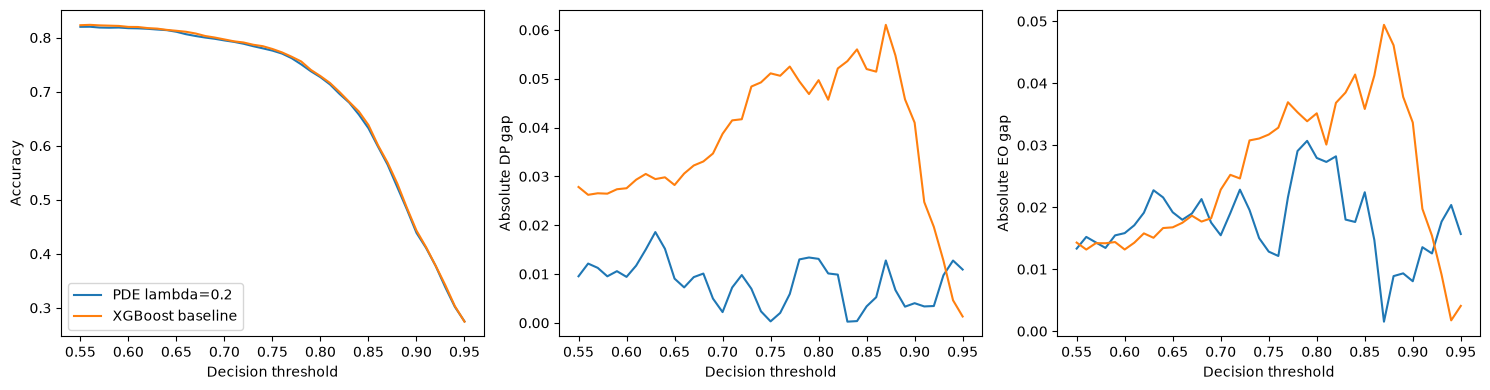

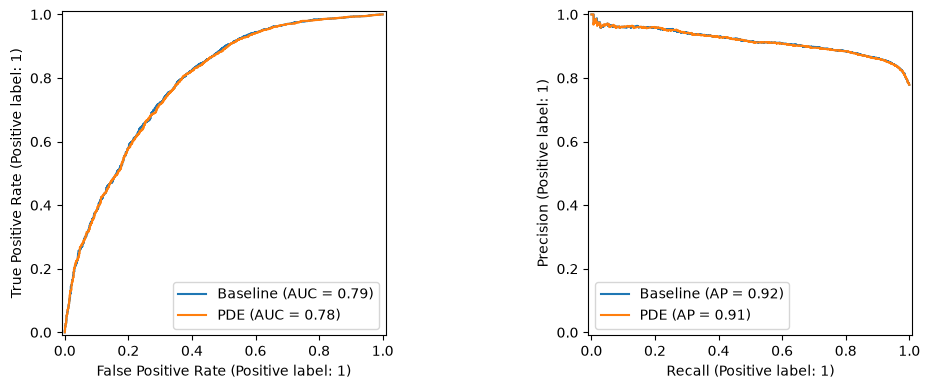

In [8]:
threshold_grid=np.linspace(.55,.95,41)
threshold_rows=[]
for label,z in [('XGBoost baseline',base['test']),('PDE lambda=0.2',pde_scores[.2])]:
    for th in threshold_grid:
        threshold_rows.append({'method':label,'threshold':th,**metrics(yt,gt,z,th)})
threshold_df=pd.DataFrame(threshold_rows)
threshold_df.to_csv(OUT/'threshold_sensitivity.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for label,sub in threshold_df.groupby('method'):
    for ax,col in zip(axes,['accuracy','abs_dp','abs_eo']):ax.plot(sub.threshold,sub[col],label=label)
for ax,col in zip(axes,['Accuracy','Absolute DP gap','Absolute EO gap']):ax.set(xlabel='Decision threshold',ylabel=col)
axes[0].legend();plt.tight_layout();fig.savefig(OUT/'threshold_sensitivity.png',dpi=180);plt.show()
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label,z in [('Baseline',base['test']),('PDE',pde_scores[.2])]:
    RocCurveDisplay.from_predictions(yt,z,name=label,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(yt,z,name=label,ax=axes[1])
plt.tight_layout();fig.savefig(OUT/'roc_pr_curves.png',dpi=180);plt.show()


## 8. Diffusion, grid resolution, and runtime sensitivity

,D,N,runtime_seconds,steps,converged,mass_error,min_density,terminal_density_gap,accuracy,balanced_accuracy,...,approval_1,tpr_0,tpr_1,fpr_0,fpr_1,dp_gap,abs_dp,abs_eo,abs_fpr,equalized_odds
0,0.0005,200,0.091489,200,False,0.0,0.0,-0.001960,0.768333,0.714489,...,0.714246,0.823073,0.803484,0.393043,0.37367,0.004845,0.004845,0.019588,0.019373,0.019588
1,0.0005,400,0.059137,200,False,0.0,0.0,-0.001906,0.768167,0.714382,...,0.714246,0.822518,0.803484,0.393043,0.37367,0.004425,0.004425,0.019034,0.019373,0.019373
2,0.0005,800,0.084499,200,False,0.0,0.0,-0.001874,0.768333,0.714489,...,0.714246,0.823073,0.803484,0.393043,0.37367,0.004845,0.004845,0.019588,0.019373,0.019588
3,0.0010,200,0.052301,200,False,0.0,0.0,-0.002977,0.769167,0.714754,...,0.716179,0.823073,0.805575,0.393043,0.37500,0.002913,0.002913,0.017498,0.018043,0.018043
4,0.0010,400,0.059531,200,False,0.0,0.0,-0.002891,0.769167,0.714754,...,0.716179,0.823073,0.805575,0.393043,0.37500,0.002913,0.002913,0.017498,0.018043,0.018043
5,0.0010,800,0.081467,200,False,0.0,0.0,-0.002840,0.769000,0.714377,...,0.716455,0.823073,0.805575,0.393043,0.37633,0.002637,0.002637,0.017498,0.016714,0.017498
6,0.0020,200,0.050342,200,False,0.0,0.0,-0.004528,0.769167,0.714214,...,0.717559,0.822518,0.806620,0.393043,0.37766,0.001112,0.001112,0.015898,0.015384,0.015898
7,0.0020,400,0.061132,200,False,0.0,0.0,-0.004381,0.769167,0.714214,...,0.717559,0.822518,0.806620,0.393043,0.37766,0.001112,0.001112,0.015898,0.015384,0.015898
8,0.0020,800,0.082723,200,False,0.0,0.0,-0.004293,0.769167,0.714214,...,0.717559,0.822518,0.806620,0.393043,0.37766,0.001112,0.001112,0.015898,0.015384,0.015898


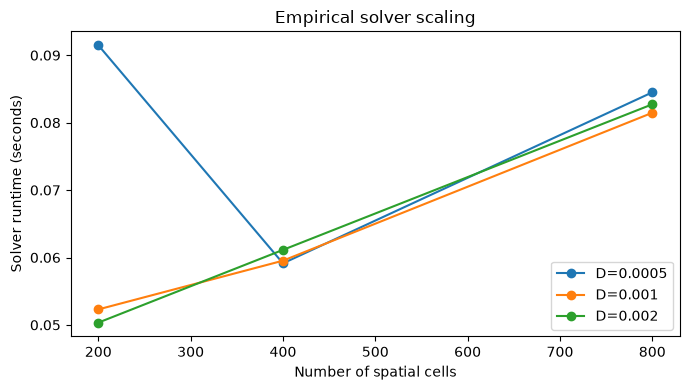

In [9]:
sensitivity=[]
for D in [.0005,.001,.002]:
    for N in [200,400,800]:
        fit=pde_fit(base['cal'],gc,tau,lam=.2,D=D,N=N,T=40.,dt=.2)
        z=pde_predict(fit,base['test'],gt)
        log=fit['log'];sensitivity.append({'D':D,'N':N,'runtime_seconds':fit['runtime'],
           'steps':fit['steps'],'converged':fit['converged'],
           'mass_error':log.mass_error.max(),'min_density':log.min_density.min(),
           'terminal_density_gap':log.density_gap.iloc[-1],**metrics(yt,gt,z,tau)})
sensitivity=pd.DataFrame(sensitivity);display(sensitivity.round(6))
sensitivity.to_csv(OUT/'diffusion_grid_sensitivity.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
for D,sub in sensitivity.groupby('D'):ax.plot(sub.N,sub.runtime_seconds,'o-',label=f'D={D}')
ax.set(xlabel='Number of spatial cells',ylabel='Solver runtime (seconds)',title='Empirical solver scaling')
ax.legend();plt.tight_layout();fig.savefig(OUT/'solver_runtime_scaling.png',dpi=180);plt.show()


## 9. Quantile-map monotonicity, rank preservation, and cross-λ behavior

In [10]:
# Monotonicity in original score is expected within each group because
# each transport map is a composition of nondecreasing CDF and quantile functions.
from scipy.stats import spearmanr
rank_rows=[]
for lam,z in pde_scores.items():
    for k in (0,1):
        mask=gt==k
        order=np.argsort(base['test'][mask],kind='stable')
        sorted_z=z[mask][order]
        violations=int(np.sum(np.diff(sorted_z)<-1e-10))
        rank_rows.append({'lambda':lam,'group':k,'monotonicity_violations':violations,
          'within_group_spearman':spearmanr(base['test'][mask],z[mask]).statistic})
rank_df=pd.DataFrame(rank_rows);display(rank_df)
assert (rank_df.monotonicity_violations==0).all()
rank_df.to_csv(OUT/'transport_monotonicity.csv',index=False)
# Cross-group global ranking need not be preserved; nor must an individual's
# score move monotonically as lambda varies.


,lambda,group,monotonicity_violations,within_group_spearman
0,0.0000,0,0,1.0
1,0.0000,1,0,1.0
2,0.0025,0,0,1.0
3,0.0025,1,0,1.0
4,0.0050,0,0,1.0
5,0.0050,1,0,1.0
6,0.0100,0,0,1.0
7,0.0100,1,0,1.0
8,0.0200,0,0,1.0
9,0.0200,1,0,1.0


## 10. Numerical time-series and fairness-energy diagnostics

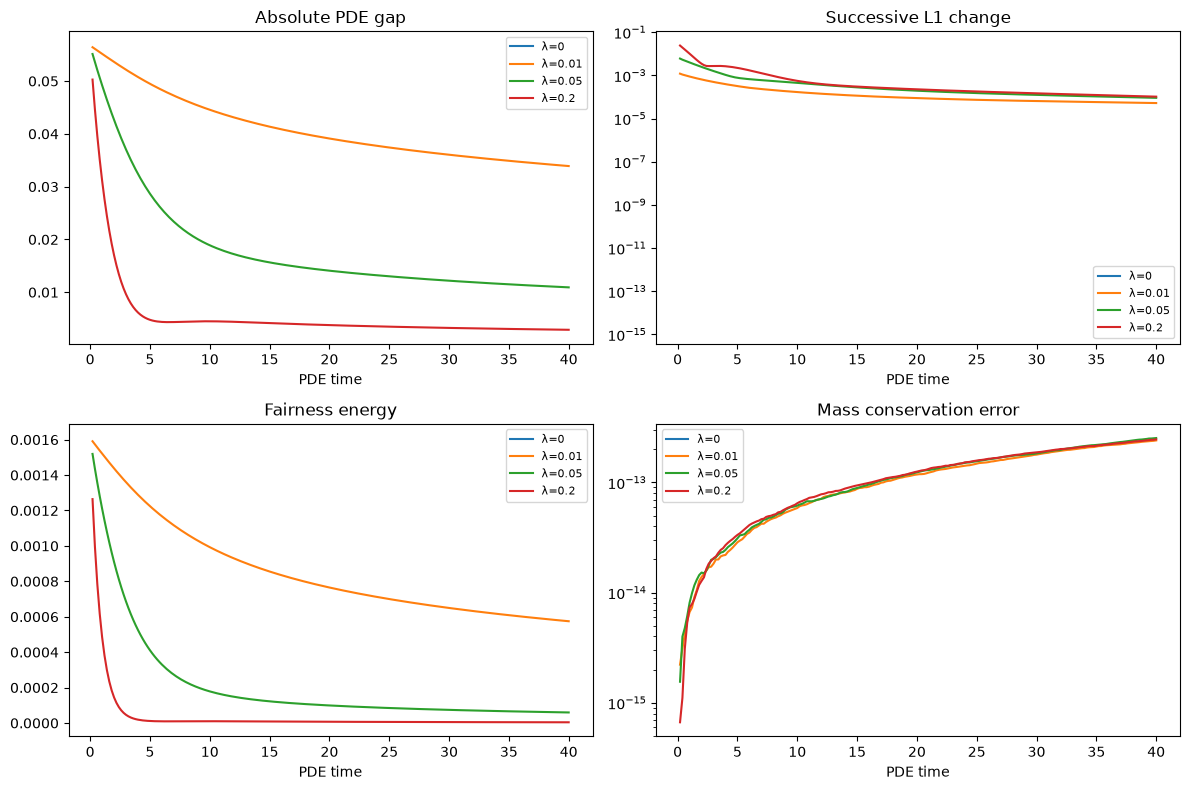

In [11]:
fig,axs=plt.subplots(2,2,figsize=(12,8))
for lam in [0,.01,.05,.2]:
    log=pde_fits[lam]['log']
    axs[0,0].plot(log.time,log.density_gap.abs(),label=f'λ={lam}')
    axs[0,1].semilogy(log.time,np.maximum(log.l1_step,1e-16),label=f'λ={lam}')
    axs[1,0].plot(log.time,log.fairness_energy,label=f'λ={lam}')
    axs[1,1].semilogy(log.time,np.maximum(log.mass_error,1e-16),label=f'λ={lam}')
for ax,title in zip(axs.ravel(),['Absolute PDE gap','Successive L1 change','Fairness energy','Mass conservation error']):
    ax.set(xlabel='PDE time',title=title);ax.legend(fontsize=8)
plt.tight_layout();fig.savefig(OUT/'pde_numerical_diagnostics.png',dpi=180);plt.show()
for lam,fit in pde_fits.items():fit['log'].to_csv(OUT/f'pde_diagnostics_lambda_{lam:g}.csv',index=False)


## 11. Independent-dataset generalizability: required follow-up

Reviewer 1 asks for a second dataset. The supplied files contain only the original UCI credit-card dataset. **No external dataset is invented or silently substituted.** To complete this request, obtain an independent credit dataset with a documented binary outcome and protected-group attribute, define its feature and label mappings, and rerun the locked train/calibration/test protocol. The original dataset supports robustness and within-dataset stability checks, but those do not replace external validation.

## 12. Complexity and manuscript reporting

For \(N\) grid cells, each time step builds two tridiagonal finite-volume operators and solves two tridiagonal linear systems. With a banded tridiagonal solver, the numerical work is \(O(N)\) per step and \(O(KN)\) for \(K\) steps, excluding score fitting and density construction. The implementation uses sparse LU; empirical timings are reported above. Transport of \(m\) scores is \(O(m\log N)\) with CDF lookup. Classifier training complexity depends on the chosen learner.

The reviewer-response manuscript should report **separately** the calibration density-integral gap, the test-set discrete approval gap, and group-specific TPR/FPR values; describe the threshold and score source used for each. Convergence flags are included so a terminal state reached by time cap is not mislabeled as numerically converged.

In [12]:
print('Output directory:',OUT.resolve())
print('Files generated:',len(list(OUT.iterdir())))
print('Key checks:', {'fairness_metric_consistency':True,'group_transport_monotonicity':True,
                     'max_mass_error':float(pde_table.max_mass_error.max())})


Output directory: /Users/olusolaolabanjo/Desktop/pde-credit-scoring/reviewer_response_outputs
Files generated: 20
Key checks: {'fairness_metric_consistency': True, 'group_transport_monotonicity': True, 'max_mass_error': 2.5279778270714814e-13}
